In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import string
import re
import nltk

from tqdm import trange
from nltk import tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.probability import FreqDist
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer

In [70]:
import warnings
warnings.filterwarnings('ignore')
nltk.download('omw-1.4', quiet=True)
sns.set_style('darkgrid')
plt.rcParams['figure.figsize'] = (17,7)
plt.rcParams['font.size'] = 18

In [71]:
data = pd.read_csv('email_spam_indo.csv')
data.head(10)

,Kategori,Pesan
0,spam,Secara alami tak tertahankan identitas perusah...
1,spam,Fanny Gunslinger Perdagangan Saham adalah Merr...
2,spam,Rumah -rumah baru yang luar biasa menjadi muda...
3,spam,4 Permintaan Khusus Pencetakan Warna Informasi...
4,spam,"Jangan punya uang, dapatkan CD perangkat lunak..."
5,spam,"Nnews yang hebat halo, selamat datang di medzo..."
6,spam,Berikut ini adalah permainan panas di Investme...
7,spam,Simpan uang Anda beli untuk mendapatkan barang...
8,spam,Tidak Terkirim: Bisnis Berbasis Rumah Untuk Or...
9,spam,Simpan uang Anda beli untuk mendapatkan barang...


In [72]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2636 entries, 0 to 2635
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Kategori  2636 non-null   str  
 1   Pesan     2636 non-null   str  
dtypes: str(2)
memory usage: 41.3 KB


In [73]:
def clean(Pesan):
    
    Pesan = Pesan.lower()
    Pesan = re.sub('[^a-z A-Z]+', '', Pesan)
    banned_words=stopwords.words('indonesian')+['-','enron','ect','vince','hou','kaminski','cc','shirley','crenshaw']
    Pesan = " ".join([word for word in Pesan.split() if word not in banned_words])
    
    return Pesan

In [74]:
data['Pesan'] = data['Pesan'].apply(clean)
data.head(10)

,Kategori,Pesan
0,spam,alami tertahankan identitas perusahaan sulit p...
1,spam,fanny gunslinger perdagangan saham merrill muz...
2,spam,rumah rumah mudah pemilik rumah disetujui pinj...
3,spam,permintaan khusus pencetakan warna informasi t...
4,spam,uang dapatkan cd perangkat lunak kompatibilita...
5,spam,nnews hebat halo selamat medzonline sh grounds...
6,spam,permainan panas investments security investmen...
7,spam,simpan uang beli barang mencoba ciall membayan...
8,spam,terkirim bisnis berbasis rumah orang tata subj...
9,spam,simpan uang beli barang mencoba ciall membayan...


In [75]:
def corpus(text):
    text_list = text.split()
    return text_list

In [76]:
data['Pesan_lists'] = data['Pesan'].apply(corpus)
data.head(10)

,Kategori,Pesan,Pesan_lists
0,spam,alami tertahankan identitas perusahaan sulit p...,"[alami, tertahankan, identitas, perusahaan, su..."
1,spam,fanny gunslinger perdagangan saham merrill muz...,"[fanny, gunslinger, perdagangan, saham, merril..."
2,spam,rumah rumah mudah pemilik rumah disetujui pinj...,"[rumah, rumah, mudah, pemilik, rumah, disetuju..."
3,spam,permintaan khusus pencetakan warna informasi t...,"[permintaan, khusus, pencetakan, warna, inform..."
4,spam,uang dapatkan cd perangkat lunak kompatibilita...,"[uang, dapatkan, cd, perangkat, lunak, kompati..."
5,spam,nnews hebat halo selamat medzonline sh grounds...,"[nnews, hebat, halo, selamat, medzonline, sh, ..."
6,spam,permainan panas investments security investmen...,"[permainan, panas, investments, security, inve..."
7,spam,simpan uang beli barang mencoba ciall membayan...,"[simpan, uang, beli, barang, mencoba, ciall, m..."
8,spam,terkirim bisnis berbasis rumah orang tata subj...,"[terkirim, bisnis, berbasis, rumah, orang, tat..."
9,spam,simpan uang beli barang mencoba ciall membayan...,"[simpan, uang, beli, barang, mencoba, ciall, m..."


In [77]:
corpus = []
for i in trange(data.shape[0], ncols=150, nrows=10, colour='green', smoothing=0.8):
    corpus += data['Pesan_lists'][i]
len(corpus)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████| 2636/2636 [00:00<00:00, 128849.46it/s]


285333

In [78]:
mostCommon = Counter(corpus).most_common(10)
mostCommon

[('com', 2193),
 ('perusahaan', 1689),
 ('memiliki', 1545),
 ('orang', 1327),
 ('email', 1271),
 ('subjek', 1264),
 ('terima', 1256),
 ('kasih', 1212),
 ('informasi', 1209),
 ('situs', 1099)]

In [79]:
words = []
freq = []
for word, count in mostCommon:
    words.append(word)
    freq.append(count)

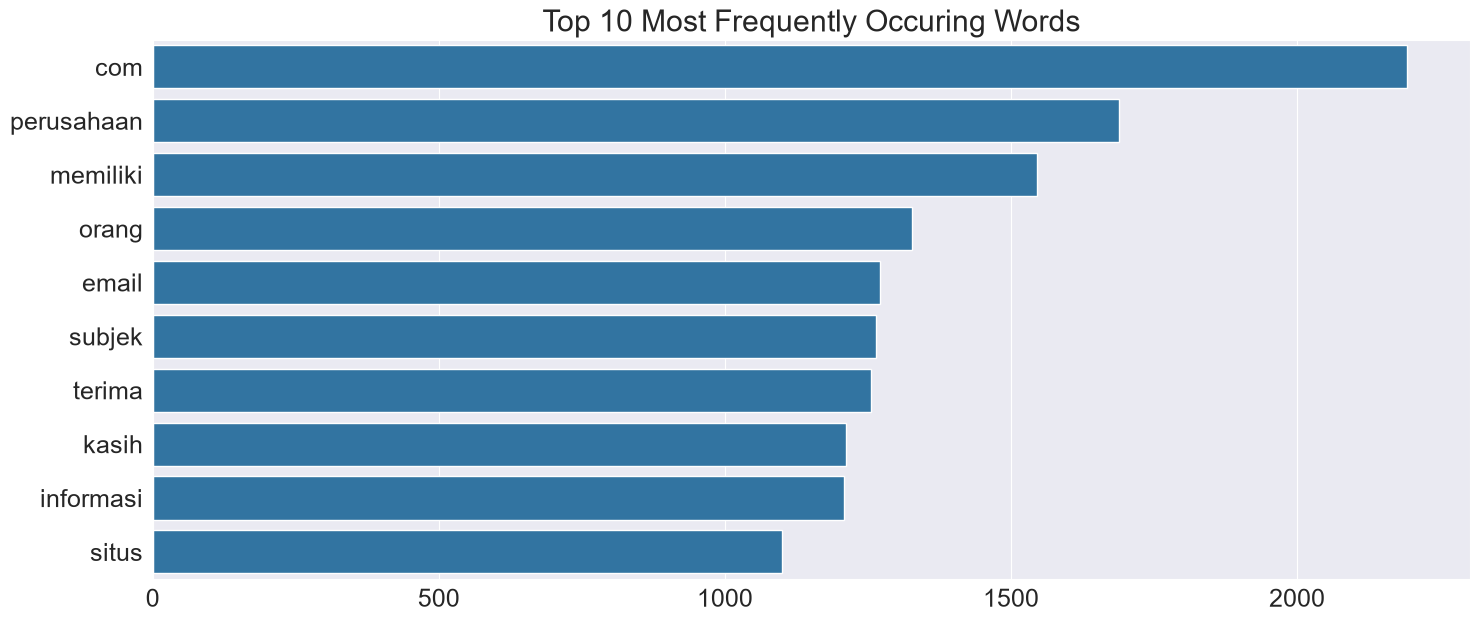

In [80]:
sns.barplot(x=freq, y=words)
plt.title('Top 10 Most Frequently Occuring Words')
plt.show()

In [81]:
cv = CountVectorizer(ngram_range=(2,2))
bigrams = cv.fit_transform(data['Pesan'])

In [82]:
count_values = bigrams.toarray().sum(axis=0)
ngram_freq = pd.DataFrame(sorted([(count_values[i], k) for k, i in cv.vocabulary_.items()], reverse = True))
ngram_freq.columns = ["frequency", "ngram"]

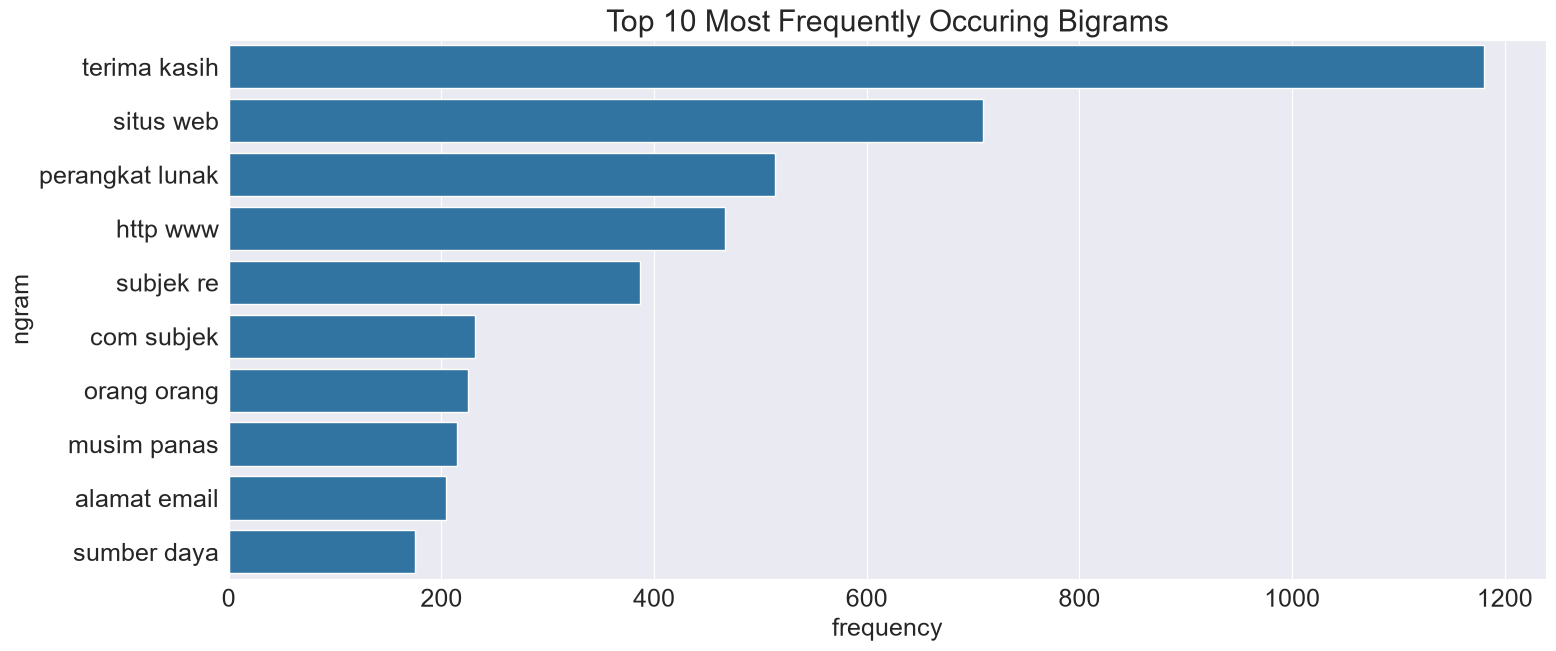

In [83]:
sns.barplot(x=ngram_freq['frequency'][:10], y=ngram_freq['ngram'][:10])
plt.title('Top 10 Most Frequently Occuring Bigrams')
plt.show()

In [84]:
cv1 = CountVectorizer(ngram_range=(3,3))
trigrams = cv1.fit_transform(data['Pesan'])
count_values = trigrams.toarray().sum(axis=0)
ngram_freq = pd.DataFrame(sorted([(count_values[i], k) for k, i in cv1.vocabulary_.items()], reverse = True))
ngram_freq.columns = ["frequency", "ngram"]

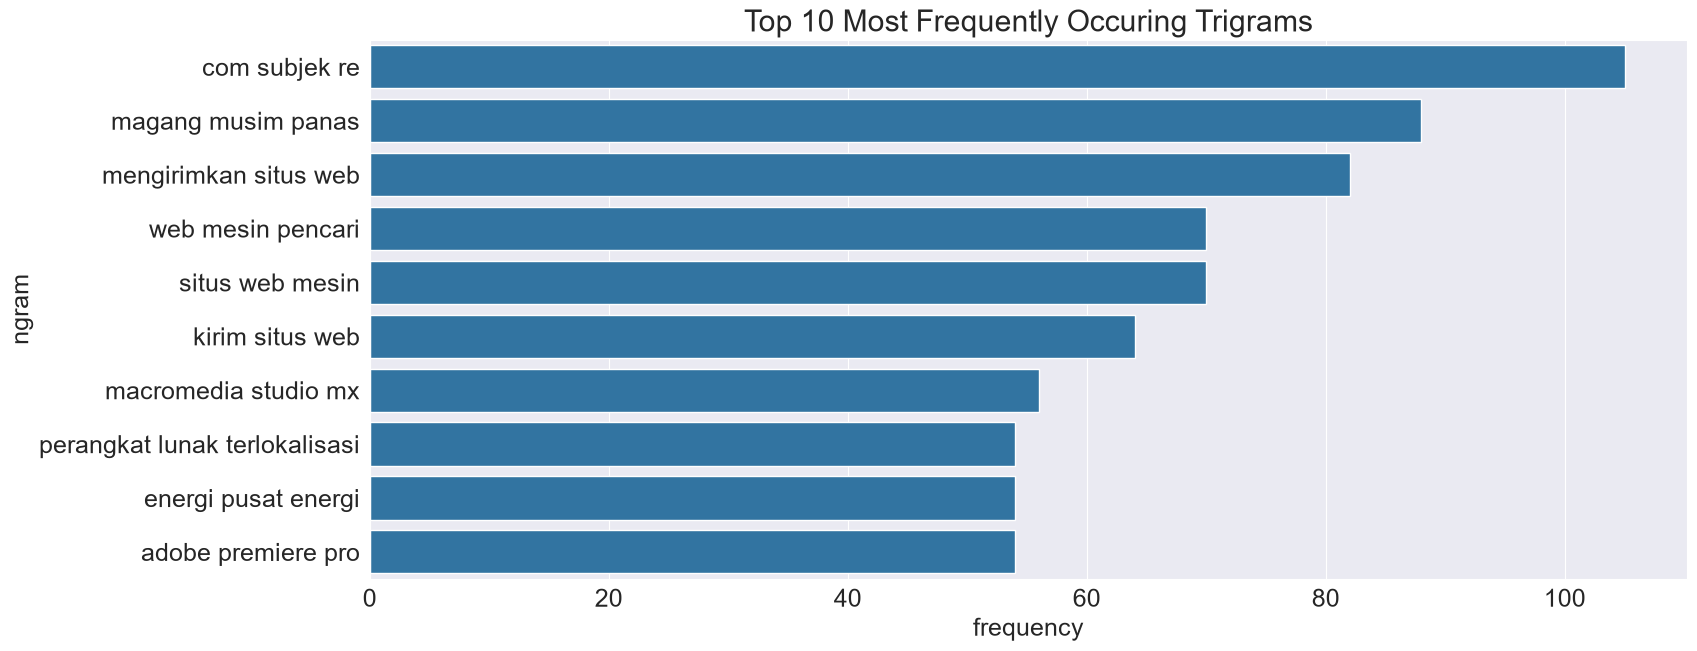

In [85]:
sns.barplot(x=ngram_freq['frequency'][:10], y=ngram_freq['ngram'][:10])
plt.title('Top 10 Most Frequently Occuring Trigrams')
plt.show()

# Spam Analysis

In [87]:
spam_df=data[data['Kategori']=='spam']
ham_df=data[data['Kategori']=='ham']

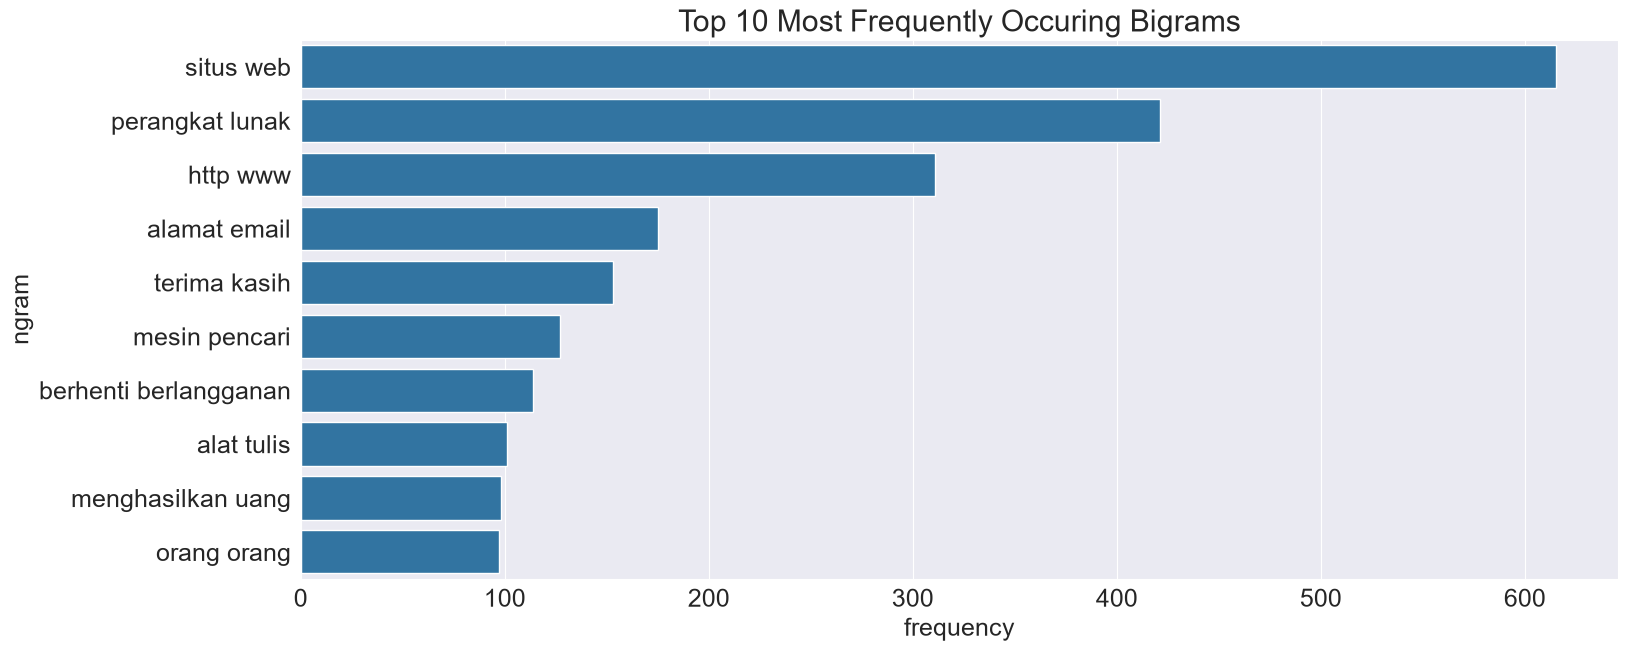

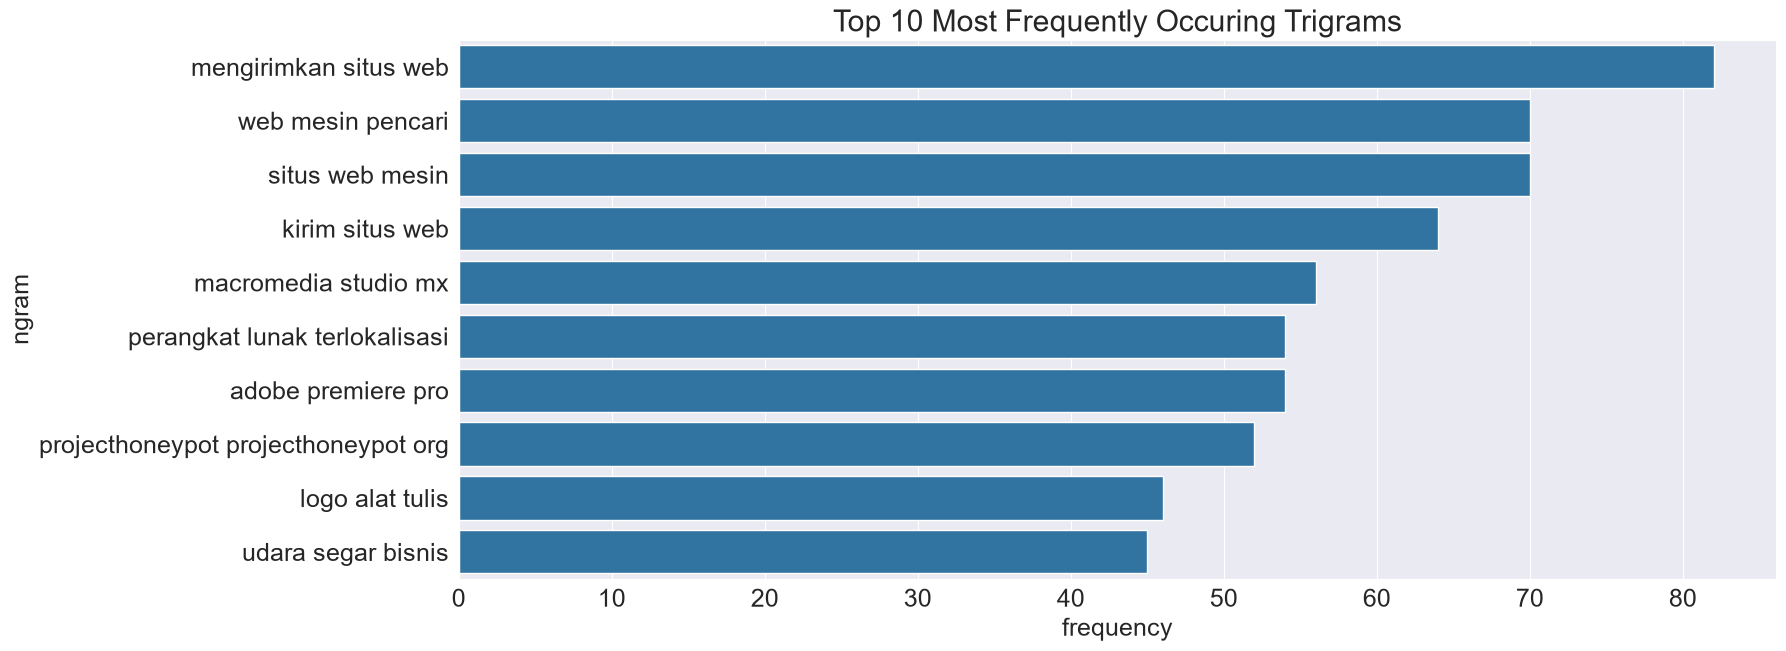

In [88]:
cv = CountVectorizer(ngram_range=(2,2))
bigrams = cv.fit_transform(spam_df['Pesan'])
count_values = bigrams.toarray().sum(axis=0)
ngram_freq = pd.DataFrame(sorted([(count_values[i], k) for k, i in cv.vocabulary_.items()], reverse = True))
ngram_freq.columns = ["frequency", "ngram"]
sns.barplot(x=ngram_freq['frequency'][:10], y=ngram_freq['ngram'][:10])
plt.title('Top 10 Most Frequently Occuring Bigrams')
plt.show()
cv1 = CountVectorizer(ngram_range=(3,3))
trigrams = cv1.fit_transform(spam_df['Pesan'])
count_values = trigrams.toarray().sum(axis=0)
ngram_freq = pd.DataFrame(sorted([(count_values[i], k) for k, i in cv1.vocabulary_.items()], reverse = True))
ngram_freq.columns = ["frequency", "ngram"]
sns.barplot(x=ngram_freq['frequency'][:10], y=ngram_freq['ngram'][:10])
plt.title('Top 10 Most Frequently Occuring Trigrams')
plt.show()

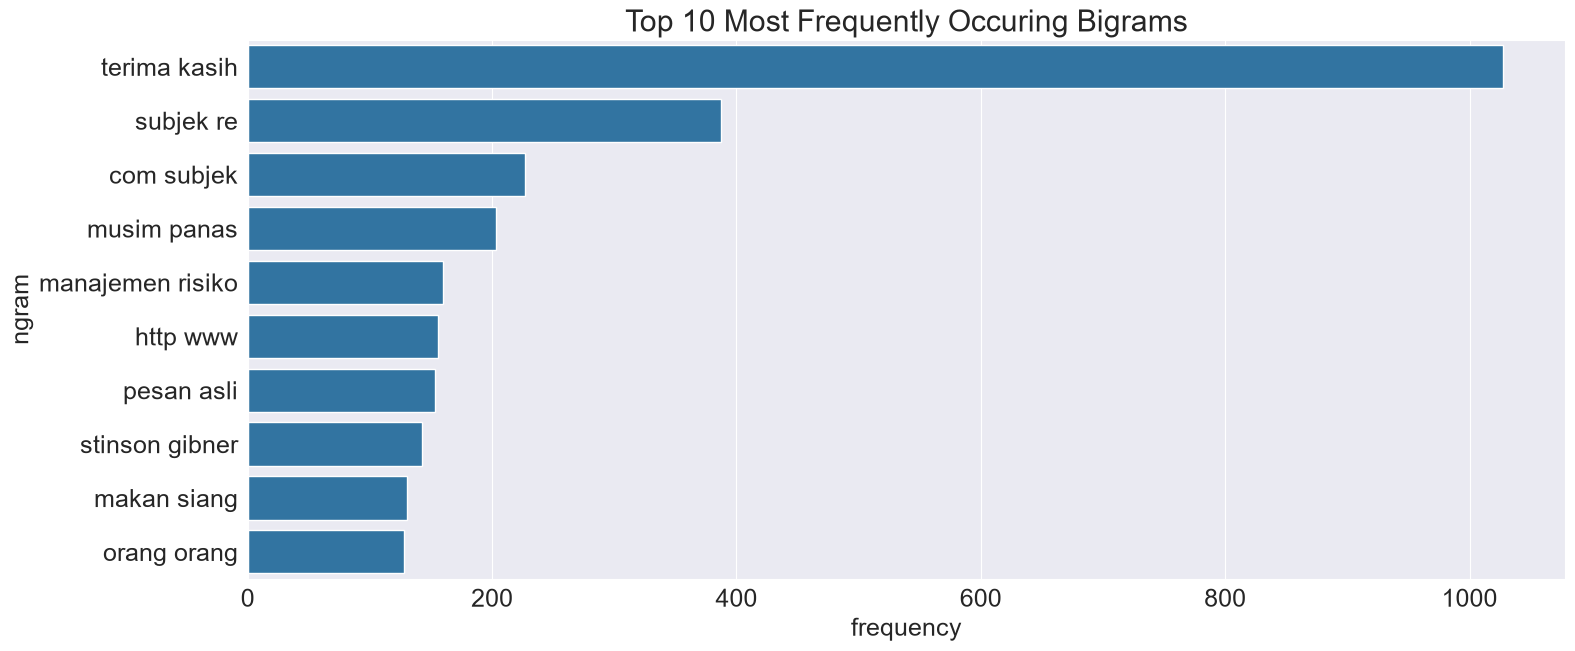

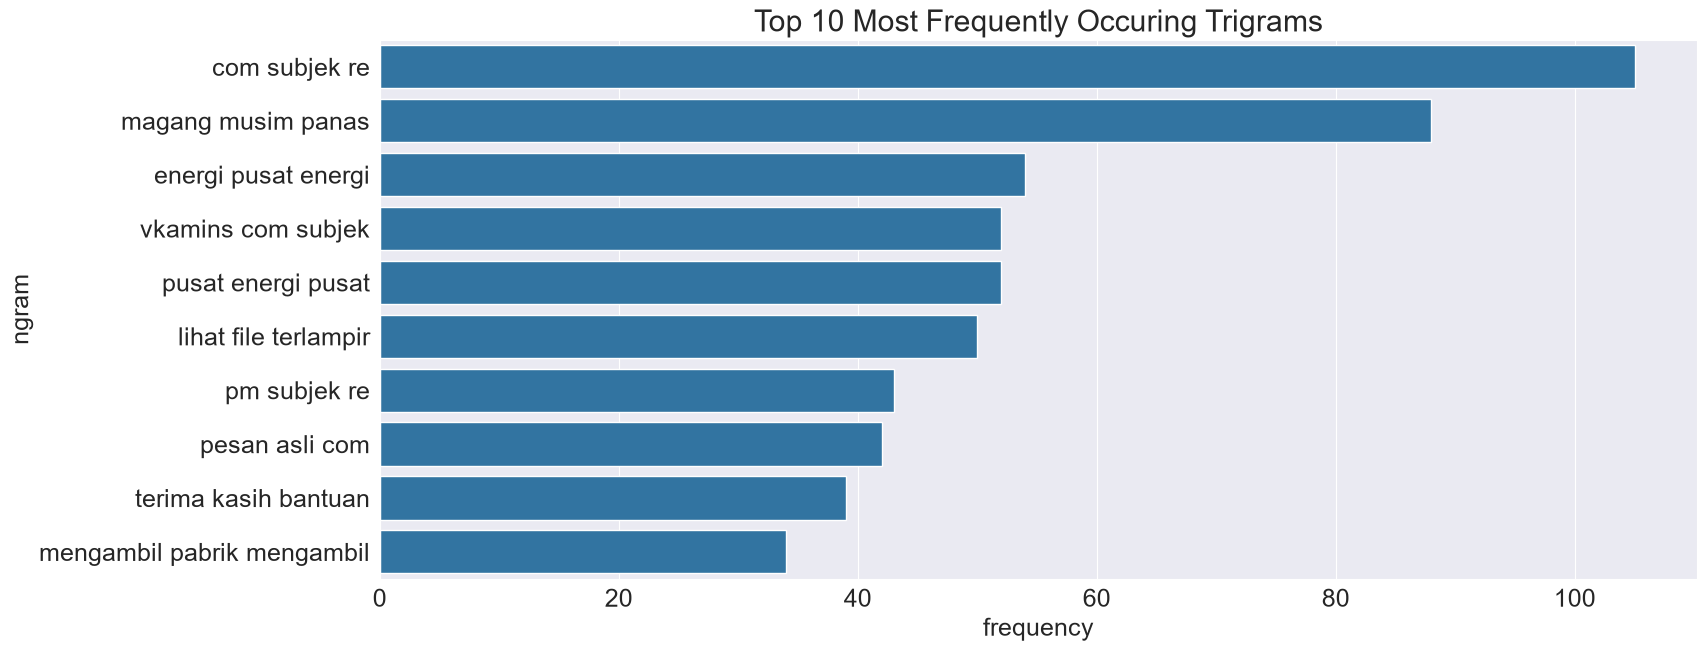

In [89]:
cv = CountVectorizer(ngram_range=(2,2))
bigrams = cv.fit_transform(ham_df['Pesan'])
count_values = bigrams.toarray().sum(axis=0)
ngram_freq = pd.DataFrame(sorted([(count_values[i], k) for k, i in cv.vocabulary_.items()], reverse = True))
ngram_freq.columns = ["frequency", "ngram"]
sns.barplot(x=ngram_freq['frequency'][:10], y=ngram_freq['ngram'][:10])
plt.title('Top 10 Most Frequently Occuring Bigrams')
plt.show()
cv1 = CountVectorizer(ngram_range=(3,3))
trigrams = cv1.fit_transform(ham_df['Pesan'])
count_values = trigrams.toarray().sum(axis=0)
ngram_freq = pd.DataFrame(sorted([(count_values[i], k) for k, i in cv1.vocabulary_.items()], reverse = True))
ngram_freq.columns = ["frequency", "ngram"]
sns.barplot(x=ngram_freq['frequency'][:10], y=ngram_freq['ngram'][:10])
plt.title('Top 10 Most Frequently Occuring Trigrams')
plt.show()